# Clustering Track — Online Retail Customer Segmentation

## 1. Problem Statement

The objective of this clustering project is to identify groups of customers with similar purchasing behaviours using the Online Retail dataset.

Clustering is an unsupervised machine learning technique, so the algorithms will identify groups without using predefined class labels.

## 2. Algorithms

The following algorithms will be implemented:

1. **K-Means Clustering:** Groups customers into a specified number of clusters by minimizing the within-cluster sum of squared distances.
2. **Agglomerative Hierarchical Clustering:** Builds a hierarchy of clusters by progressively merging similar groups of customers.

Different linkage strategies will be compared for hierarchical clustering.

## 3. Evaluation and Visualisation

The models will be evaluated using Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index. The analysis will also include an Elbow curve, a dendrogram, PCA-based two-dimensional cluster visualisations, and a t-SNE visualisation.

The cluster labels generated by the algorithms will be used to analyse customer groups, not as training targets.

In [2]:
#1.Importing Required Libraries
# Import libraries for data handling
import pandas as pd
import numpy as np

# Import libraries for visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Import clustering algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering

# Import evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Import dimensionality reduction techniques
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Import dendrogram functionality
from scipy.cluster.hierarchy import linkage, dendrogram

# Set random seed for reproducibility
RANDOM_STATE = 42

# Set plot style
sns.set_style("whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


## 4. Loading the Preprocessed Dataset

The customer-level feature dataset is loaded for clustering. The scaled version is used because K-Means and hierarchical clustering rely on distances, and features with larger numerical ranges can otherwise dominate the results.

Customer identifiers, if present, are excluded from the feature matrix because they identify customers rather than describe purchasing behaviour. The data is checked for missing, infinite, and non-numeric values before model fitting.

In [3]:
# Load the scaled customer feature dataset
data_path = "../data/online_retail_customer_features_scaled.csv"

df = pd.read_csv(data_path)

# Display dataset information
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (4334, 8)

First five rows:


,Customer ID,Recency,Frequency,Monetary,UniqueProducts,AvgUnitPrice,AvgOrderValue,CancelRate
0,12346,1.460438,-0.969937,2.699980,-2.539645,-1.935292,2.827721,2.376804
1,12347,-2.038956,1.118736,1.486110,0.977876,-0.193931,1.126615,-0.636919
2,12348,0.371964,0.410601,0.578535,-0.404963,-2.495008,0.357575,-0.636919
3,12349,-0.623847,-0.969937,0.590128,0.662795,0.894944,2.358348,-0.636919
4,12350,1.423017,-0.969937,-0.730098,-0.634491,-1.228933,0.073343,-0.636919



Column names:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'UniqueProducts', 'AvgUnitPrice', 'AvgOrderValue', 'CancelRate']

Data types:
Customer ID         int64
Recency           float64
Frequency         float64
Monetary          float64
UniqueProducts    float64
AvgUnitPrice      float64
AvgOrderValue     float64
CancelRate        float64
dtype: object

Missing values:
Customer ID       0
Recency           0
Frequency         0
Monetary          0
UniqueProducts    0
AvgUnitPrice      0
AvgOrderValue     0
CancelRate        0
dtype: int64

Duplicate rows: 0


In [4]:
#Prepare numerical features
# Make a copy to preserve the original loaded dataset
cluster_data = df.copy()

# Remove identifier columns if they exist
# Customer IDs must not influence distance calculations
id_columns = [
    col for col in cluster_data.columns
    if col.strip().lower().replace("_", " ") in [
        "customer id", "customerid", "customer"
    ]
]

cluster_data = cluster_data.drop(columns=id_columns)

# Keep numerical columns only
X = cluster_data.select_dtypes(include=[np.number]).copy()

# Remove columns that contain no variation
constant_columns = [
    col for col in X.columns if X[col].nunique(dropna=False) <= 1
]

if constant_columns:
    print("Removing constant columns:", constant_columns)
    X = X.drop(columns=constant_columns)

# Check for infinite values and convert them to missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Report remaining data-quality issues
print("Missing values by feature:")
print(X.isnull().sum())

# Fill missing numerical values using the median, if required
X = X.fillna(X.median())

# Ensure the data is suitable for clustering
assert X.shape[1] >= 2, "At least two numerical features are required."
assert X.shape[0] >= 3, "At least three records are required."
assert np.isfinite(X.to_numpy()).all(), "Non-finite values remain."

print("\nFinal feature matrix shape:", X.shape)
display(X.head())

Missing values by feature:
Recency           0
Frequency         0
Monetary          0
UniqueProducts    0
AvgUnitPrice      0
AvgOrderValue     0
CancelRate        0
dtype: int64

Final feature matrix shape: (4334, 7)


,Recency,Frequency,Monetary,UniqueProducts,AvgUnitPrice,AvgOrderValue,CancelRate
0,1.460438,-0.969937,2.699980,-2.539645,-1.935292,2.827721,2.376804
1,-2.038956,1.118736,1.486110,0.977876,-0.193931,1.126615,-0.636919
2,0.371964,0.410601,0.578535,-0.404963,-2.495008,0.357575,-0.636919
3,-0.623847,-0.969937,0.590128,0.662795,0.894944,2.358348,-0.636919
4,1.423017,-0.969937,-0.730098,-0.634491,-1.228933,0.073343,-0.636919


In [5]:
#Verify Scaling
# Inspect feature ranges to verify the preprocessing output
scaling_check = pd.DataFrame({
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Mean": X.mean(),
    "Standard Deviation": X.std()
})

display(scaling_check.round(3))

,Minimum,Maximum,Mean,Standard Deviation
Recency,-2.341,1.563,0.0,1.0
Frequency,-0.970,3.160,0.0,1.0
Monetary,-2.147,2.700,0.0,1.0
UniqueProducts,-2.540,2.070,0.0,1.0
AvgUnitPrice,-2.506,3.301,0.0,1.0
AvgOrderValue,-2.630,2.828,-0.0,1.0
CancelRate,-0.637,4.185,-0.0,1.0


## 5. K-Means Clustering and Elbow Method

K-Means partitions the customers into \(k\) clusters. Each customer is assigned to the cluster whose centroid is nearest to it.

The Elbow method evaluates different values of \(k\) using inertia, which measures the sum of squared distances between customers and their assigned cluster centroids.

As \(k\) increases, inertia generally decreases. The preferred value is often near the point where the decrease starts becoming less pronounced. This is a heuristic, so the final choice will also consider the clustering evaluation metrics.

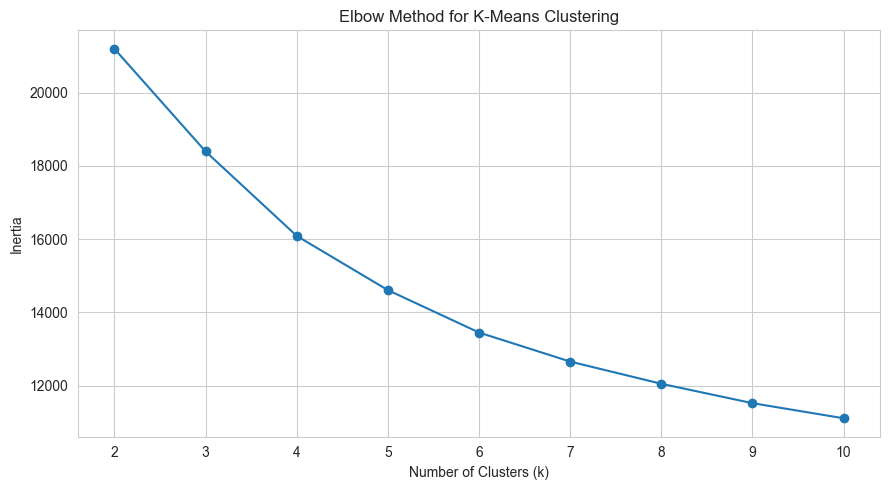

In [6]:
#Plot the Elbow curve
# Test a range of cluster counts
k_values = range(2, 11)
inertias = []

for k in k_values:
    # Train K-Means for the current k
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    kmeans.fit(X)

    # Store inertia for the Elbow plot
    inertias.append(kmeans.inertia_)

# Plot inertia against the number of clusters
plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker="o")

plt.title("Elbow Method for K-Means Clustering")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

## 6. Selecting and Fitting the K-Means Model

After examining the Elbow curve, select a reasonable number of clusters. The code below uses four clusters as an initial value. This is a starting point for evaluation, not a claim that four is automatically optimal.

The resulting cluster labels will be added to a separate results DataFrame, leaving the feature matrix unchanged.

In [7]:
#Train K-Means
# Initial cluster count; revise after examining the Elbow curve
BEST_K = 4

# Fit the K-Means algorithm
kmeans_model = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X)

# Store the results separately
cluster_results = pd.DataFrame(index=X.index)
cluster_results["KMeans_Cluster"] = kmeans_labels

print("K-Means model fitted successfully.")
print("\nNumber of customers in each cluster:")
print(cluster_results["KMeans_Cluster"].value_counts().sort_index())

print("\nCluster centroids:")
display(pd.DataFrame(
    kmeans_model.cluster_centers_,
    columns=X.columns
).round(3))

K-Means model fitted successfully.

Number of customers in each cluster:
KMeans_Cluster
0    1491
1     655
2    1150
3    1038
Name: count, dtype: int64

Cluster centroids:


,Recency,Frequency,Monetary,UniqueProducts,AvgUnitPrice,AvgOrderValue,CancelRate
0,0.122,-0.375,-0.108,0.054,-0.154,0.253,-0.596
1,0.315,-0.288,0.002,-0.120,0.212,0.301,1.826
2,-0.924,1.301,1.174,0.989,-0.055,0.426,0.226
3,0.650,-0.724,-1.148,-1.099,0.149,-1.025,-0.544


## 7. Agglomerative Hierarchical Clustering

Agglomerative clustering is a bottom-up hierarchical method. Initially, each customer is treated as a separate cluster. The algorithm repeatedly merges clusters until the required number of clusters is obtained.

Different linkage strategies define how the distance between two clusters is calculated:

- **Ward linkage:** merges clusters to minimise the increase in within-cluster variance.
- **Complete linkage:** uses the maximum pairwise distance between clusters.
- **Average linkage:** uses the average pairwise distance between clusters.

The three strategies will be compared using the same number of clusters and the required evaluation metrics. Ward linkage requires Euclidean distance, so the default Euclidean metric is used for all three comparisons.

In [8]:
#Fit and compare linkage strategies
# Compare three linkage strategies
linkage_methods = ["ward", "complete", "average"]

hierarchical_labels = {}
hierarchical_models = {}

for method in linkage_methods:
    # Create the hierarchical clustering model
    model = AgglomerativeClustering(
        n_clusters=BEST_K,
        linkage=method,
        metric="euclidean"
    )

    # Fit the model and obtain cluster labels
    labels = model.fit_predict(X)

    # Save the model and labels
    hierarchical_models[method] = model
    hierarchical_labels[method] = labels

    print(f"\nLinkage strategy: {method}")
    print(pd.Series(labels).value_counts().sort_index())

# Use Ward linkage as the initial hierarchical result
cluster_results["Agglomerative_Ward"] = hierarchical_labels["ward"]

print("\nHierarchical clustering completed.")


Linkage strategy: ward
0    1006
1    1269
2    1264
3     795
Name: count, dtype: int64

Linkage strategy: complete
0    1279
1    2274
2     608
3     173
Name: count, dtype: int64

Linkage strategy: average
0    4245
1      62
2      25
3       2
Name: count, dtype: int64

Hierarchical clustering completed.


## 8. Dendrogram for Hierarchical Clustering

A dendrogram displays the hierarchy of cluster merges. The vertical axis represents the distance at which clusters are merged, while the horizontal axis represents the observations or groups in the hierarchy.

Large vertical gaps between merges can suggest useful places to cut the tree into clusters.

Since a dendrogram becomes difficult to read for a large dataset, a reproducible sample of customers is used for visualisation. The dendrogram is illustrative; the linkage comparison and evaluation metrics will be calculated using the full feature matrix.

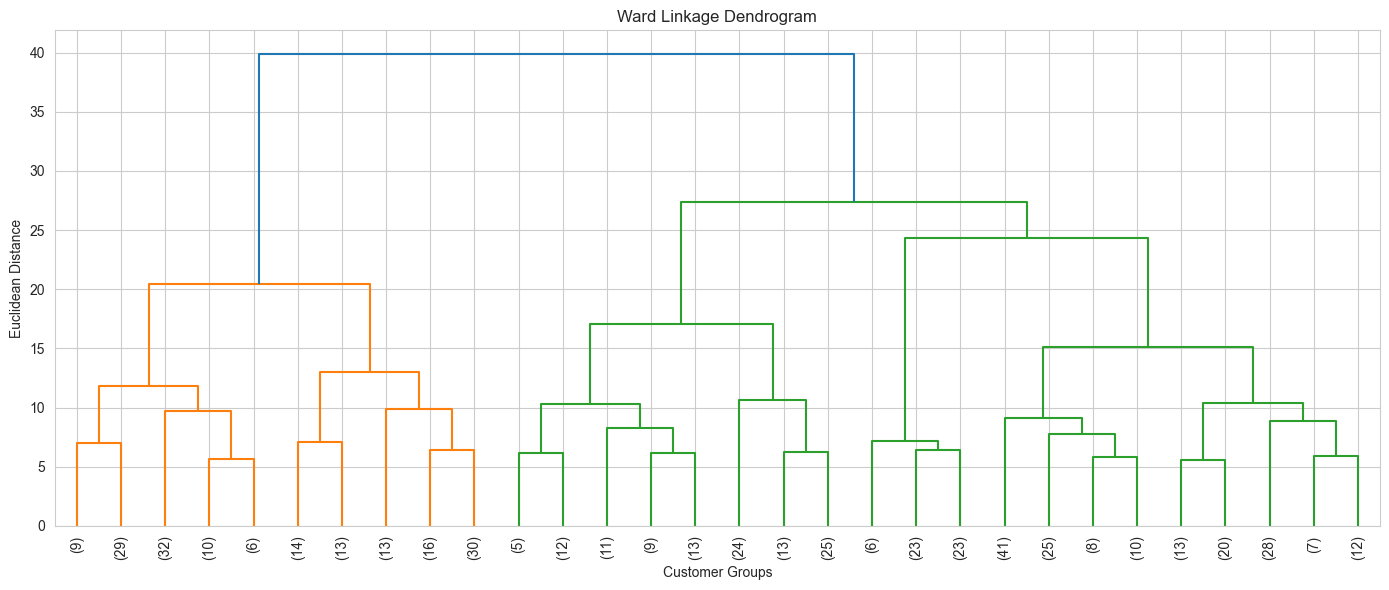

In [9]:
#Plot the dendrogram
# Use a reproducible sample for dendrogram visualisation
# Hierarchical linkage matrices require a distance calculation
DENDROGRAM_SAMPLE_SIZE = min(500, len(X))

X_dendrogram = X.sample(
    n=DENDROGRAM_SAMPLE_SIZE,
    random_state=RANDOM_STATE
)

# Construct the linkage matrix using Ward linkage
linkage_matrix = linkage(
    X_dendrogram.to_numpy(),
    method="ward",
    metric="euclidean"
)

# Plot the dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90
)

plt.title("Ward Linkage Dendrogram")
plt.xlabel("Customer Groups")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

## 9. Evaluation Metrics

Clustering performance will be compared using three mandatory metrics.

1. **Silhouette Score:** measures how well each customer fits within its own cluster compared with other clusters. Higher values are generally better.
2. **Davies–Bouldin Index:** measures the similarity between clusters relative to their separation. Lower values are generally better.
3. **Calinski–Harabasz Index:** compares between-cluster dispersion with within-cluster dispersion. Higher values are generally better.

These metrics do not require ground-truth labels. All models are evaluated on the same feature matrix to make their results comparable. The number of clusters must be between 2 and the number of observations minus 1 for these metrics to be valid.

In [10]:
#Compare all clustering results
# Prepare all algorithms for evaluation
all_cluster_labels = {
    "K-Means": kmeans_labels,
    "Agglomerative - Ward": hierarchical_labels["ward"],
    "Agglomerative - Complete": hierarchical_labels["complete"],
    "Agglomerative - Average": hierarchical_labels["average"]
}

evaluation_results = []

for model_name, labels in all_cluster_labels.items():
    number_of_clusters = len(np.unique(labels))

    # The metrics require at least two clusters
    # and fewer clusters than observations
    if 1 < number_of_clusters < len(X):
        evaluation_results.append({
            "Algorithm": model_name,
            "Number of Clusters": number_of_clusters,
            "Silhouette Score": silhouette_score(X, labels),
            "Davies-Bouldin Index": davies_bouldin_score(X, labels),
            "Calinski-Harabasz Index": calinski_harabasz_score(X, labels)
        })

# Create a single comparison table
evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,4,0.2038,1.5205,1278.5433
1,Agglomerative - Ward,4,0.1501,1.8344,1018.0659
2,Agglomerative - Complete,4,0.0949,1.7238,752.3054
3,Agglomerative - Average,4,0.1987,1.1000,71.7364


## 10. PCA-Based Cluster Visualisation

Principal Component Analysis (PCA) reduces the numerical feature space to two principal components while retaining as much variance as possible in those two dimensions.

The two-dimensional representation makes it easier to visualise the cluster assignments produced by K-Means and Agglomerative Clustering.

PCA is used here for visualisation only. The clustering algorithms are fitted using the original scaled feature matrix, not the two-dimensional PCA representation.

Total variance explained by two components: 0.6188


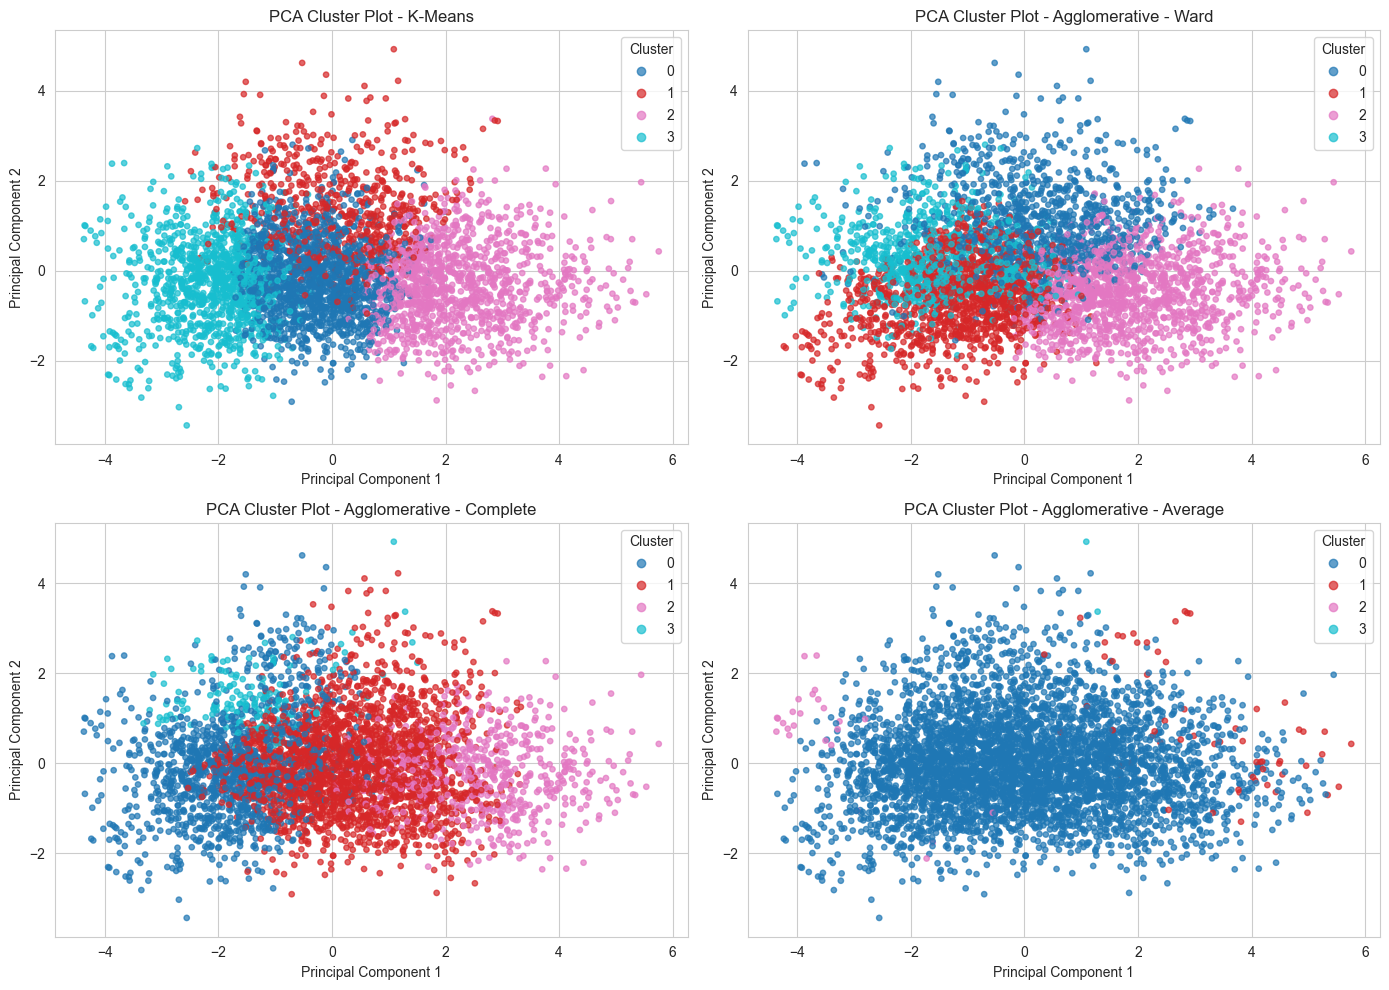

In [11]:
# PCA visualisation for every evaluated clustering method

pca_labels = {
    "K-Means": kmeans_labels,
    "Agglomerative - Ward": hierarchical_labels["ward"],
    "Agglomerative - Complete": hierarchical_labels["complete"],
    "Agglomerative - Average": hierarchical_labels["average"]
}

# Create a 2D PCA representation
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print(
    "Total variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

# Create one PCA plot per clustering method
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (name, labels) in zip(axes, pca_labels.items()):

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="tab10",
        s=15,
        alpha=0.7
    )

    ax.set_title(f"PCA Cluster Plot - {name}")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

    ax.legend(
        *scatter.legend_elements(),
        title="Cluster"
    )

plt.tight_layout()
plt.show()

## 11. t-SNE Visualisation

t-distributed Stochastic Neighbor Embedding (t-SNE) is a nonlinear dimensionality-reduction technique that helps visualise local similarities between customers in two dimensions.

The following visualisation uses K-Means cluster assignments to colour the observations. The t-SNE coordinates are generated only for visualisation; they are not used to fit the clustering model.

A reproducible sample is used if the dataset is large because t-SNE can be computationally expensive. The sample size and random seed are fixed for reproducibility.

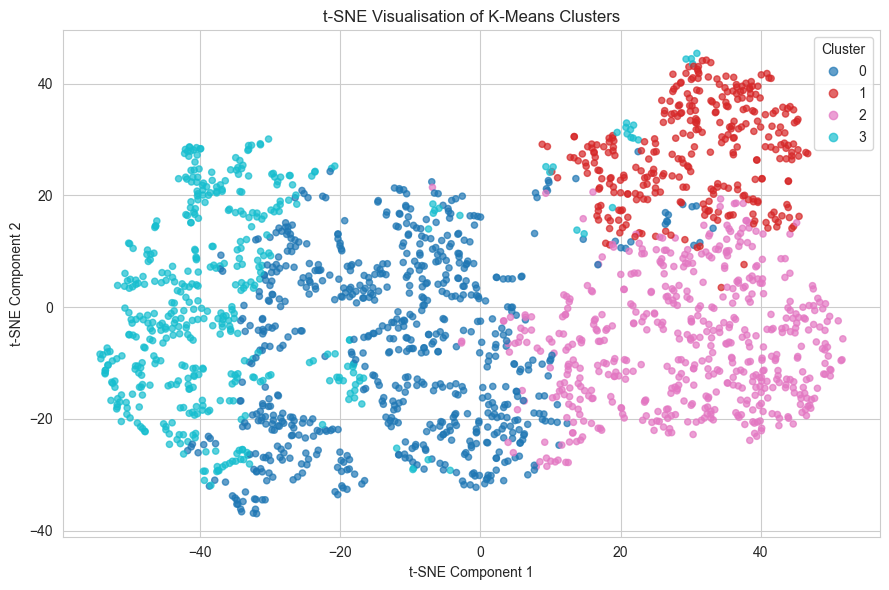

In [12]:
#t-SNE plot
# Use a sample for efficient t-SNE visualisation
TSNE_SAMPLE_SIZE = min(2000, len(X))

sample_indices = X.sample(
    n=TSNE_SAMPLE_SIZE,
    random_state=RANDOM_STATE
).index

X_tsne_input = X.loc[sample_indices]
tsne_labels = pd.Series(
    kmeans_labels,
    index=X.index
).loc[sample_indices].to_numpy()

# Set a valid perplexity for the sample size
perplexity_value = min(30, TSNE_SAMPLE_SIZE - 1)

# Reduce the data to two dimensions
tsne = TSNE(
    n_components=2,
    perplexity=perplexity_value,
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_tsne_input)

# Plot the t-SNE representation
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=tsne_labels,
    cmap="tab10",
    s=20,
    alpha=0.7
)

plt.title("t-SNE Visualisation of K-Means Clusters")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()

## 12. Results and Interpretation

The clustering results are compared using the three internal evaluation metrics. K-Means is evaluated using the selected number of clusters, while Agglomerative Clustering is evaluated using Ward, complete, and average linkage strategies.

The Elbow curve helps assess a suitable cluster count, the dendrogram illustrates the hierarchy of merges, and PCA and t-SNE plots provide visual representations of the resulting groups.

The final interpretation will be based on the actual metric values, cluster sizes, and customer feature profiles observed after running the notebook. No algorithm will be declared the best before examining the results.

### Conclusion

This analysis applies two required unsupervised learning algorithms to customer-level purchasing features. Comparing the clustering methods and their evaluation metrics helps assess how effectively each approach separates customers with similar purchasing behaviours.

In [13]:
#Cluster sizes and customer profiles
# Summarise the number of customers assigned to each cluster
print("K-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print("\nAgglomerative Ward cluster sizes:")
print(pd.Series(hierarchical_labels["ward"]).value_counts().sort_index())

# Add the K-Means assignments to the feature data
kmeans_profile = X.copy()
kmeans_profile["Cluster"] = kmeans_labels

# Compare average feature values by cluster
print("\nAverage customer feature values for each K-Means cluster:")
display(
    kmeans_profile.groupby("Cluster")
    .mean()
    .round(3)
)

# Display the final evaluation table
print("\nFinal clustering comparison:")
display(evaluation_df.round(4))

K-Means cluster sizes:
0    1491
1     655
2    1150
3    1038
Name: count, dtype: int64

Agglomerative Ward cluster sizes:
0    1006
1    1269
2    1264
3     795
Name: count, dtype: int64

Average customer feature values for each K-Means cluster:


,Recency,Frequency,Monetary,UniqueProducts,AvgUnitPrice,AvgOrderValue,CancelRate
Cluster,,,,,,,
0,0.122,-0.375,-0.108,0.054,-0.154,0.253,-0.596
1,0.314,-0.286,0.003,-0.118,0.211,0.301,1.825
2,-0.924,1.302,1.174,0.990,-0.054,0.426,0.225
3,0.650,-0.724,-1.148,-1.099,0.149,-1.025,-0.544



Final clustering comparison:


,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,4,0.2038,1.5205,1278.5433
1,Agglomerative - Ward,4,0.1501,1.8344,1018.0659
2,Agglomerative - Complete,4,0.0949,1.7238,752.3054
3,Agglomerative - Average,4,0.1987,1.1000,71.7364


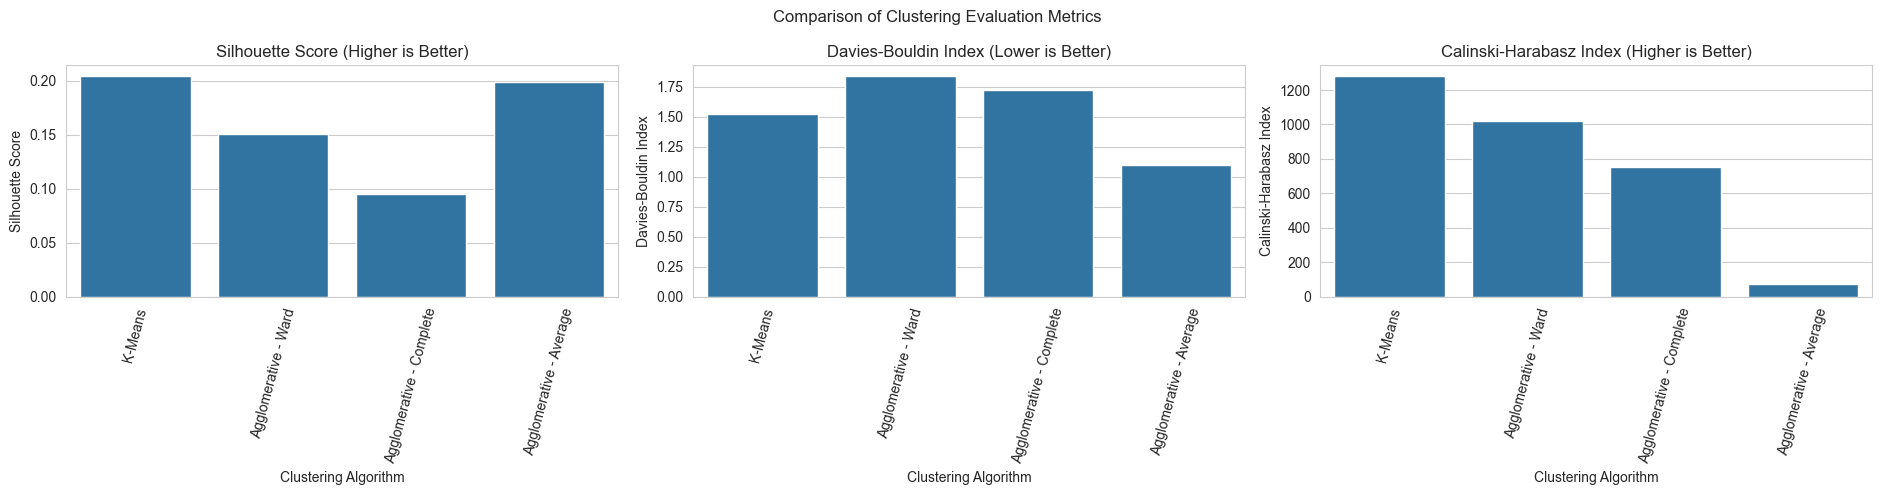

In [14]:
# Visualise the three mandatory clustering evaluation metrics

metrics = [
    ("Silhouette Score", "Silhouette Score (Higher is Better)"),
    ("Davies-Bouldin Index", "Davies-Bouldin Index (Lower is Better)"),
    ("Calinski-Harabasz Index", "Calinski-Harabasz Index (Higher is Better)")
]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (metric, title) in zip(axes, metrics):

    # Plot each algorithm's evaluation score
    sns.barplot(
        data=evaluation_df,
        x="Algorithm",
        y=metric,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Clustering Algorithm")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=75)

plt.suptitle("Comparison of Clustering Evaluation Metrics")
plt.tight_layout()
plt.show()

### Silhouette Score Analysis for K-Means

The Silhouette Score is calculated for different values of \(k\). This helps assess cluster cohesion and separation and provides additional evidence when selecting the number of clusters.

The preferred value of \(k\) should be selected by considering both the Silhouette Score and the Elbow curve, along with the interpretability of the resulting customer segments.

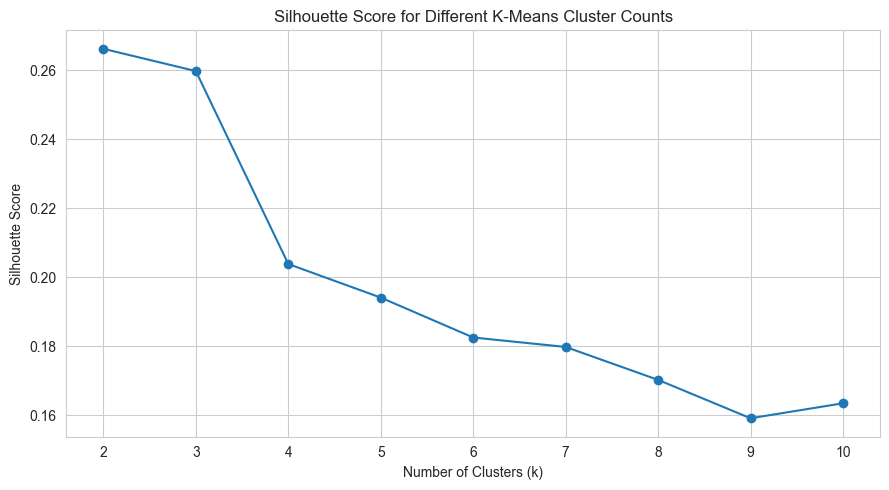

In [15]:
#Silhouette Score Analysis for K-Means
from sklearn.metrics import silhouette_score

# Evaluate K-Means for different cluster counts
silhouette_values = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)
    silhouette_values.append(score)

# Plot Silhouette Score against k
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different K-Means Cluster Counts")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.tight_layout()
plt.show()

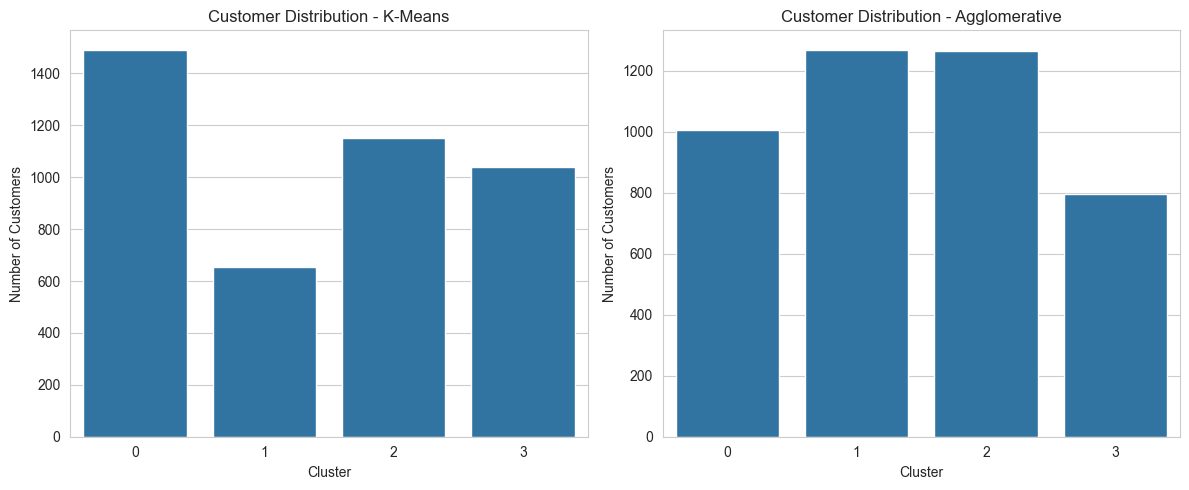

In [16]:
#Visualise the number of customers in each cluster
# Compare cluster sizes for K-Means and Ward linkage

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    x=kmeans_labels,
    ax=axes[0]
)
axes[0].set_title("Customer Distribution - K-Means")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Number of Customers")

sns.countplot(
    x=hierarchical_labels["ward"],
    ax=axes[1]
)
axes[1].set_title("Customer Distribution - Agglomerative")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [17]:

import os
import joblib

# Create the models folder
os.makedirs("../models", exist_ok=True)

# Check that the training cells have run
assert "kmeans_model" in globals(), "Run Cell 9 first."
assert "hierarchical_models" in globals(), "Run Cell 11 first."

# Collect the four fitted clustering models
clustering_models = {
    "K-Means": kmeans_model,
    "Agglomerative - Ward": hierarchical_models["ward"],
    "Agglomerative - Complete": hierarchical_models["complete"],
    "Agglomerative - Average": hierarchical_models["average"]
}

# Save all models
model_path = "../models/clustering_models.pkl"

joblib.dump(clustering_models, model_path)

print("Clustering models saved successfully!")
print("Models saved:", len(clustering_models))
print("File location:", os.path.abspath(model_path))


Clustering models saved successfully!
Models saved: 4
File location: c:\Users\manin\OneDrive\Desktop\ML-Capstone-Hotel-Booking-Demand-1\models\clustering_models.pkl


In [18]:
#Verifying models

import joblib
import os

model_path = "../models/clustering_models.pkl"

print("File exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    saved_models = joblib.load(model_path)

    print("\nSaved models:")
    for name in saved_models:
        print("-", name)

    print("\nTotal models:", len(saved_models))


File exists: True

Saved models:
- K-Means
- Agglomerative - Ward
- Agglomerative - Complete
- Agglomerative - Average

Total models: 4
